<div style="background:#0d1117;border-radius:10px;padding:20px 30px;margin-bottom:6px;display:flex;align-items:center;justify-content:space-between;gap:40px;flex-wrap:wrap;">
  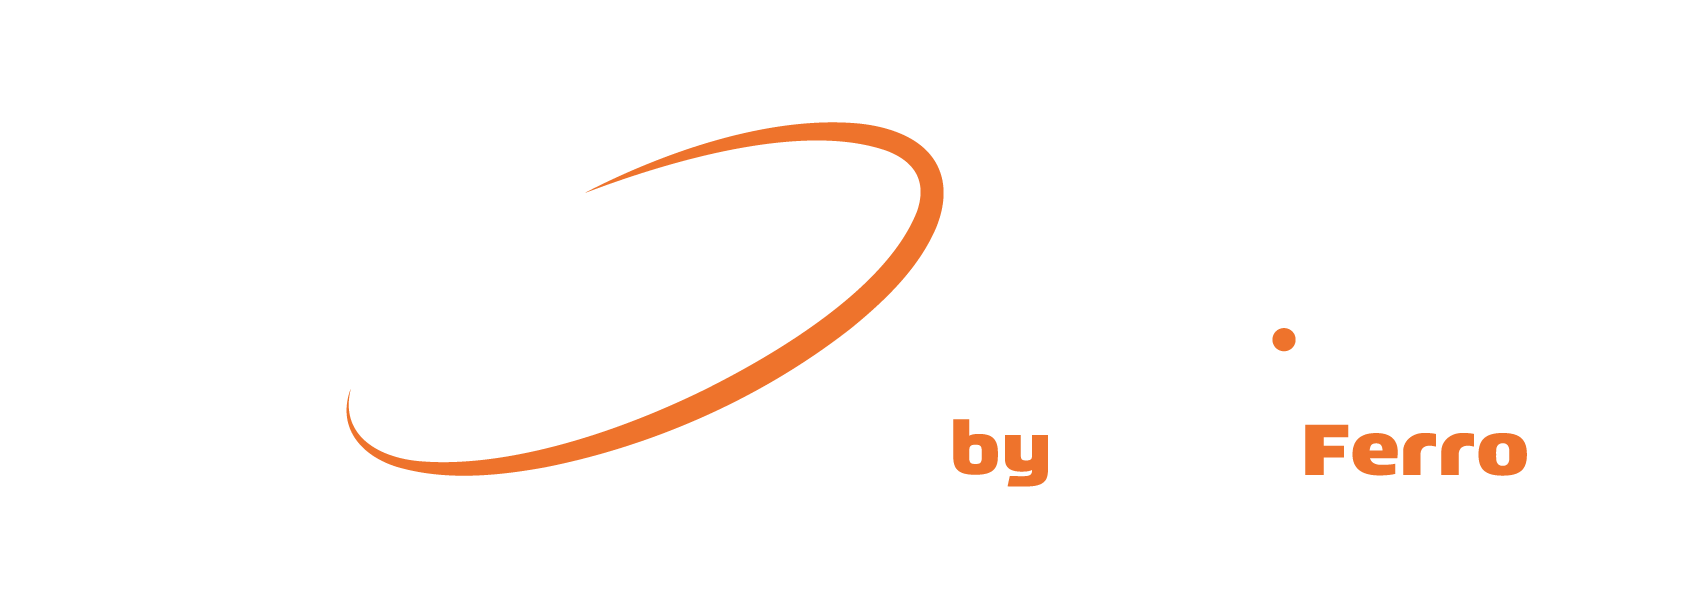
  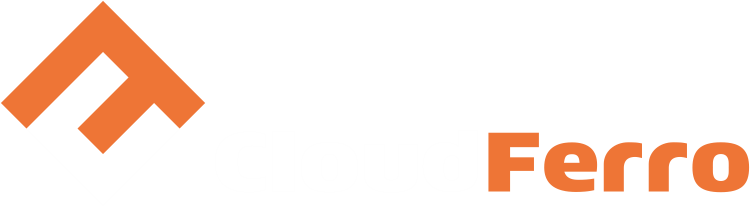
</div>

## Tessera Embeddings v1.0: PCA & Change Detection

Analyze Tessera land embeddings for a selected point in Europe across multiple years.

The notebook reads data directly from /eodata/geoAI-embeddings/Tessera/Tessera-Embeddings-v1.0.

Workflow:

1. Find the tile containing the selected coordinates.
2. Load and dequantize the 128-band embeddings.
3. Use PCA to generate RGB composites for each year.
4. Calculate and visualize changes between consecutive years.
5. Optionally use KMeans to compare land-cover patterns over time.

Configuration: Set AOI_LAT, AOI_LON and YEARS in the first cell.

Note: The dataset covers Europe only.

## Running on CREODIAS

CREODIAS provides direct access to Earth observation data through the read-only /eodata mount available on its virtual machines. This allows notebooks to read source files without downloading or staging them.

AI embedding collections are stored under /eodata/geoAI-embeddings.


## Setup

In [43]:
# OPTIONAL — only needed if the imports below fail (e.g. `ModuleNotFoundError` or an
# `attr`/`attrs` conflict). Uncomment the block, run this cell on its own, then restart
# the kernel before running the rest of the notebook.\n
# import subprocess, sys
# subprocess.run([
#     sys.executable, "-m", "pip", "install", "--user", "-q",
#     "numpy==2.2.6", "matplotlib==3.10.9", "scikit-learn==1.7.2",
#     "rasterio==1.4.4", "affine==3.0.0", "attrs>=22",
# ], check=True)
# print("Installed. Restarting kernel...")
#
# import IPython
# IPython.get_ipython().kernel.do_shutdown(restart=True)
# print("Kernel restarted — run the notebook from the top.")

In [44]:
import os
import math
import warnings

import numpy as np
import matplotlib.pyplot as plt

import rasterio
from rasterio.errors import RasterioIOError

from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

warnings.filterwarnings("ignore")
plt.rcParams["figure.facecolor"] = "white"

## Configuration

In [45]:
AOI_LAT = 52.1866   # e.g. East Warsaw
AOI_LON = 21.2934 
# Years to compare (change detection runs between consecutive entries) (2017-2024)
YEARS = [2017, 2020, 2024]

DATA_ROOT = "/eodata/geoAI-embeddings/Tessera/Tessera-Embeddings-v1.0"

GRID_STEP_DEG = 0.1        
GRID_OFFSET_DEG = 0.05    


def grid_label(coord, step=GRID_STEP_DEG, offset=GRID_OFFSET_DEG):
    """Round a coordinate to the center of its grid cell, formatted as in the tile name."""
    cell_index = math.floor((coord - offset) / step + 0.5)
    return round(cell_index * step + offset, 2)


GRID_LON = grid_label(AOI_LON)
GRID_LAT = grid_label(AOI_LAT)

print(f"Point: lat={AOI_LAT}, lon={AOI_LON}")
print(f"Grid tile: grid_{GRID_LON:g}_{GRID_LAT:g}")
print(f"Years: {YEARS}")

Point: lat=52.1866, lon=21.2934
Grid tile: grid_21.25_52.15
Years: [2017, 2020, 2024]


## Tile paths

Each tile lives in its own folder: `{year}/Tessera_{year}_v1.0_grid_{lon}_{lat}/`, containing the embedding GeoTIFF and a companion per-pixel scale GeoTIFF used to dequantize it.

In [46]:
def tile_dir(year, data_root=DATA_ROOT, lon=GRID_LON, lat=GRID_LAT):
    return os.path.join(data_root, str(year), f"Tessera_{year}_v1.0_grid_{lon:g}_{lat:g}")


def tile_path(year):
    return os.path.join(tile_dir(year), f"grid_{GRID_LON:g}_{GRID_LAT:g}.tif")


def scales_path(year):
    return os.path.join(tile_dir(year), f"grid_{GRID_LON:g}_{GRID_LAT:g}_scales.tif")


for y in YEARS:
    print(tile_path(y))

/eodata/geoAI-embeddings/Tessera/Tessera-Embeddings-v1.0/2017/Tessera_2017_v1.0_grid_21.25_52.15/grid_21.25_52.15.tif
/eodata/geoAI-embeddings/Tessera/Tessera-Embeddings-v1.0/2020/Tessera_2020_v1.0_grid_21.25_52.15/grid_21.25_52.15.tif
/eodata/geoAI-embeddings/Tessera/Tessera-Embeddings-v1.0/2024/Tessera_2024_v1.0_grid_21.25_52.15/grid_21.25_52.15.tif


## Sanity check

Inspects one tile before loading everything: band count (embedding dimensionality), dtype, CRS, resolution. The embedding is stored as `int8`, quantized per pixel - the scale file converts it back to the true float embedding (`value = int8_data * scale`).

In [47]:
def open_safely(path, retries=3):
    """/eodata is backed by s3fs and can be flaky — a few retries on open."""
    last_err = None
    for _ in range(retries):
        try:
            return rasterio.open(path)
        except RasterioIOError as e:
            last_err = e
    raise last_err


sample_path = tile_path(YEARS[0])
print(f"File: {sample_path}")

try:
    sample_ds = open_safely(sample_path)
except RasterioIOError as e:
    raise RuntimeError(
        f"Could not open {sample_path} — this is a data availability issue for this "
        "tile/year, not the point coordinates. Try a different point/year, or check whether "
        f"the point falls within Europe.\nUnderlying error: {e}"
    )

N_BANDS = sample_ds.count
print(f"Bands (embedding dimensionality): {N_BANDS}")
print(f"dtype: {sample_ds.dtypes[0]}")
print(f"CRS: {sample_ds.crs}")
print(f"Resolution (CRS units/px): {sample_ds.res}")
print(f"Tile bounds: {sample_ds.bounds}")
sample_ds.close()

File: /eodata/geoAI-embeddings/Tessera/Tessera-Embeddings-v1.0/2017/Tessera_2017_v1.0_grid_21.25_52.15/grid_21.25_52.15.tif
Bands (embedding dimensionality): 128
dtype: int8
CRS: EPSG:32634
Resolution (CRS units/px): (10.0, 10.0)
Tile bounds: BoundingBox(left=513668.83012704167, bottom=5772175.5750856, right=520548.83012704167, top=5783325.5750856)


## Load and dequantize the tile for each year

In [48]:
def load_tile(year):
    path = tile_path(year)
    try:
        ds = open_safely(path)
    except RasterioIOError as e:
        raise RuntimeError(f"{year}: could not open {path}.\nUnderlying error: {e}")
    raw = ds.read()                
    transform = ds.transform
    ds.close()

    with open_safely(scales_path(year)) as scale_ds:
        scale = scale_ds.read(1)      

    embedding = raw.astype(np.float32) * scale[np.newaxis, :, :]
    return embedding, transform


aoi_stacks = {}   
aoi_transform = None

for year in YEARS:
    print(f"Loading {year}...")
    arr, transform = load_tile(year)
    aoi_stacks[year] = arr
    aoi_transform = transform
    print(f"  shape: {arr.shape}")

min_h = min(a.shape[1] for a in aoi_stacks.values())
min_w = min(a.shape[2] for a in aoi_stacks.values())
for year in YEARS:
    aoi_stacks[year] = aoi_stacks[year][:, :min_h, :min_w]

print(f"\nFinal tile shape (bands, H, W): {aoi_stacks[YEARS[0]].shape}")

Loading 2017...
  shape: (128, 1115, 688)
Loading 2020...
  shape: (128, 1115, 688)
Loading 2024...
  shape: (128, 1115, 688)

Final tile shape (bands, H, W): (128, 1115, 688)


## PCA composite per year

PCA is fit jointly across all years so the resulting colors are directly comparable between panels — a color shift between years reflects an actual embedding change rather than an arbitrary re-rotation of the PCA axes.

Explained variance (PC1..PC3): [0.25851673 0.13385563 0.07442765]


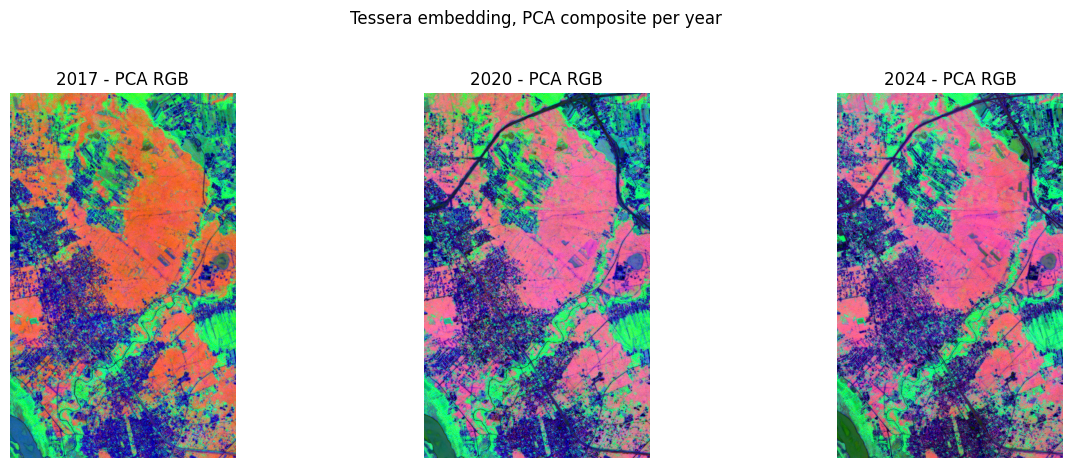

In [49]:
H, W = aoi_stacks[YEARS[0]].shape[1:]

all_pixels = np.concatenate(
    [aoi_stacks[y].reshape(N_BANDS, -1).T for y in YEARS], axis=0
)

n_components = min(3, N_BANDS)
pca = PCA(n_components=n_components)
pca.fit(all_pixels)
print(f"Explained variance (PC1..PC{n_components}): {pca.explained_variance_ratio_}")


def to_rgb(pixels_pca):
    """Scale PCA components to [0,1] per channel using percentile clipping."""
    out = np.zeros_like(pixels_pca)
    for c in range(pixels_pca.shape[-1]):
        lo, hi = np.percentile(pixels_pca[..., c], [2, 98])
        out[..., c] = np.clip((pixels_pca[..., c] - lo) / max(hi - lo, 1e-6), 0, 1)
    return out


pca_rgb_per_year = {}
for y in YEARS:
    px = aoi_stacks[y].reshape(N_BANDS, -1).T
    px_pca = pca.transform(px).reshape(H, W, n_components)
    if n_components < 3:
        px_pca = np.repeat(px_pca, 3, axis=-1)[..., :3]
    pca_rgb_per_year[y] = to_rgb(px_pca)

fig, axes = plt.subplots(1, len(YEARS), figsize=(4.5 * len(YEARS), 4.5))
if len(YEARS) == 1:
    axes = [axes]
for ax, y in zip(axes, YEARS):
    ax.imshow(pca_rgb_per_year[y])
    ax.set_title(f"{y} - PCA RGB")
    ax.axis("off")
fig.suptitle("Tessera embedding, PCA composite per year", y=1.03)
plt.tight_layout()
plt.show()

## Change detection

Euclidean distance between embedding vectors at each pixel, for every pair of consecutive years. A high value indicates a large shift in the embedding at that location - e.g. land-cover change, construction, deforestation, flooding.

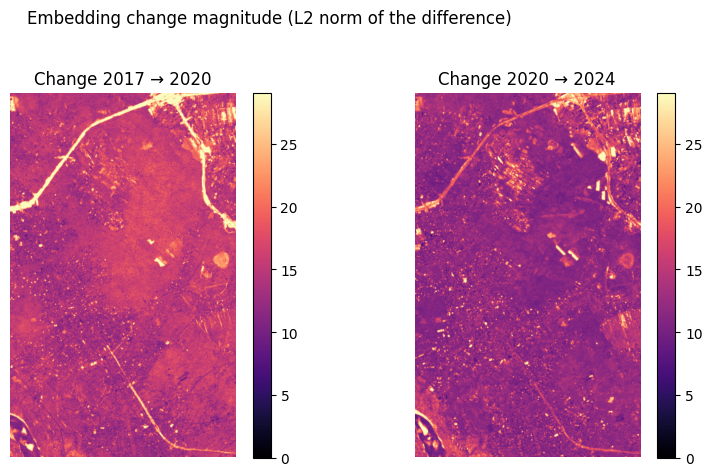

In [50]:
year_pairs = list(zip(YEARS[:-1], YEARS[1:]))
change_maps = {}

for y0, y1 in year_pairs:
    diff = aoi_stacks[y1] - aoi_stacks[y0]
    magnitude = np.linalg.norm(diff, axis=0)
    change_maps[(y0, y1)] = magnitude

n_pairs = len(year_pairs)
fig, axes = plt.subplots(1, n_pairs, figsize=(4.5 * n_pairs, 4.5))
if n_pairs == 1:
    axes = [axes]

vmax = np.percentile(np.concatenate([m.ravel() for m in change_maps.values()]), 99)
for ax, (y0, y1) in zip(axes, year_pairs):
    im = ax.imshow(change_maps[(y0, y1)], cmap="magma", vmin=0, vmax=vmax)
    ax.set_title(f"Change {y0} → {y1}")
    ax.axis("off")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
fig.suptitle("Embedding change magnitude (L2 norm of the difference)", y=1.03)
plt.tight_layout()
plt.show()

### Change hotspots

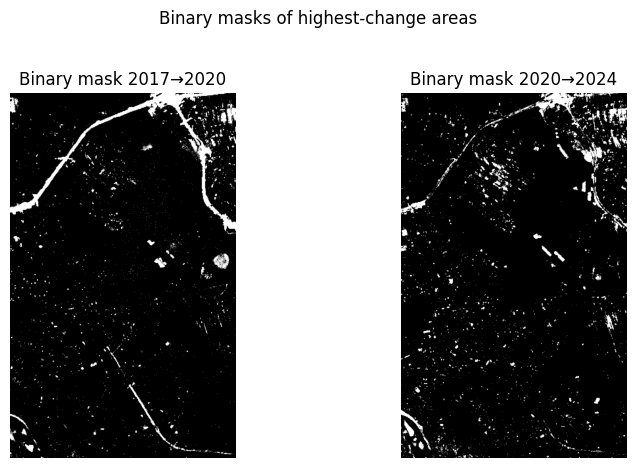

In [51]:
CHANGE_PERCENTILE = 95

fig, axes = plt.subplots(1, n_pairs, figsize=(4.5 * n_pairs, 4.5))
if n_pairs == 1:
    axes = [axes]

for ax, (y0, y1) in zip(axes, year_pairs):
    mag = change_maps[(y0, y1)]
    thresh = np.percentile(mag, CHANGE_PERCENTILE)
    mask = mag >= thresh

    ax.imshow(mask, cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Binary mask {y0}→{y1}")
    ax.axis("off")

fig.suptitle("Binary masks of highest-change areas", y=1.03)
plt.tight_layout()
plt.show()

## Clustering 

KMeans fit jointly across all years for consistent labels, then applied per year - useful for spotting where a location switched cluster 

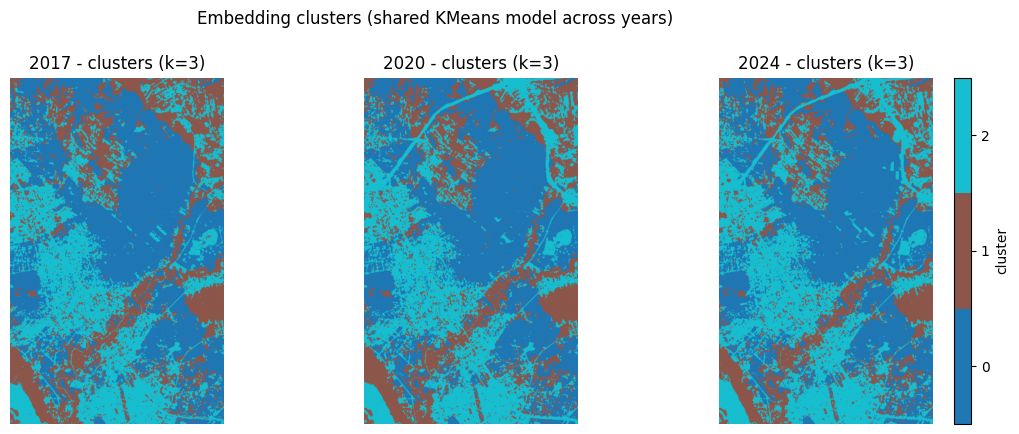

In [52]:
N_CLUSTERS = 3

kmeans = KMeans(n_clusters=N_CLUSTERS, random_state=0, n_init=10)
kmeans.fit(all_pixels)

cmap = plt.get_cmap("tab10", N_CLUSTERS)

fig, axes = plt.subplots(1, len(YEARS), figsize=(4.5 * len(YEARS), 4.5))
if len(YEARS) == 1:
    axes = [axes]

cluster_maps = {}
for ax, y in zip(axes, YEARS):
    px = aoi_stacks[y].reshape(N_BANDS, -1).T
    labels = kmeans.predict(px).reshape(H, W)
    cluster_maps[y] = labels
    im = ax.imshow(labels, cmap=cmap, vmin=-0.5, vmax=N_CLUSTERS - 0.5)
    ax.set_title(f"{y} - clusters (k={N_CLUSTERS})")
    ax.axis("off")

cbar = fig.colorbar(im, ax=axes, ticks=range(N_CLUSTERS), fraction=0.02, pad=0.02)
cbar.set_label("cluster")
fig.suptitle("Embedding clusters (shared KMeans model across years)", y=1.03)
plt.show()

<div style="background:#0d1117;border-radius:10px;padding:16px 30px;margin-top:10px;display:flex;align-items:center;justify-content:space-between;gap:40px;flex-wrap:wrap;">
  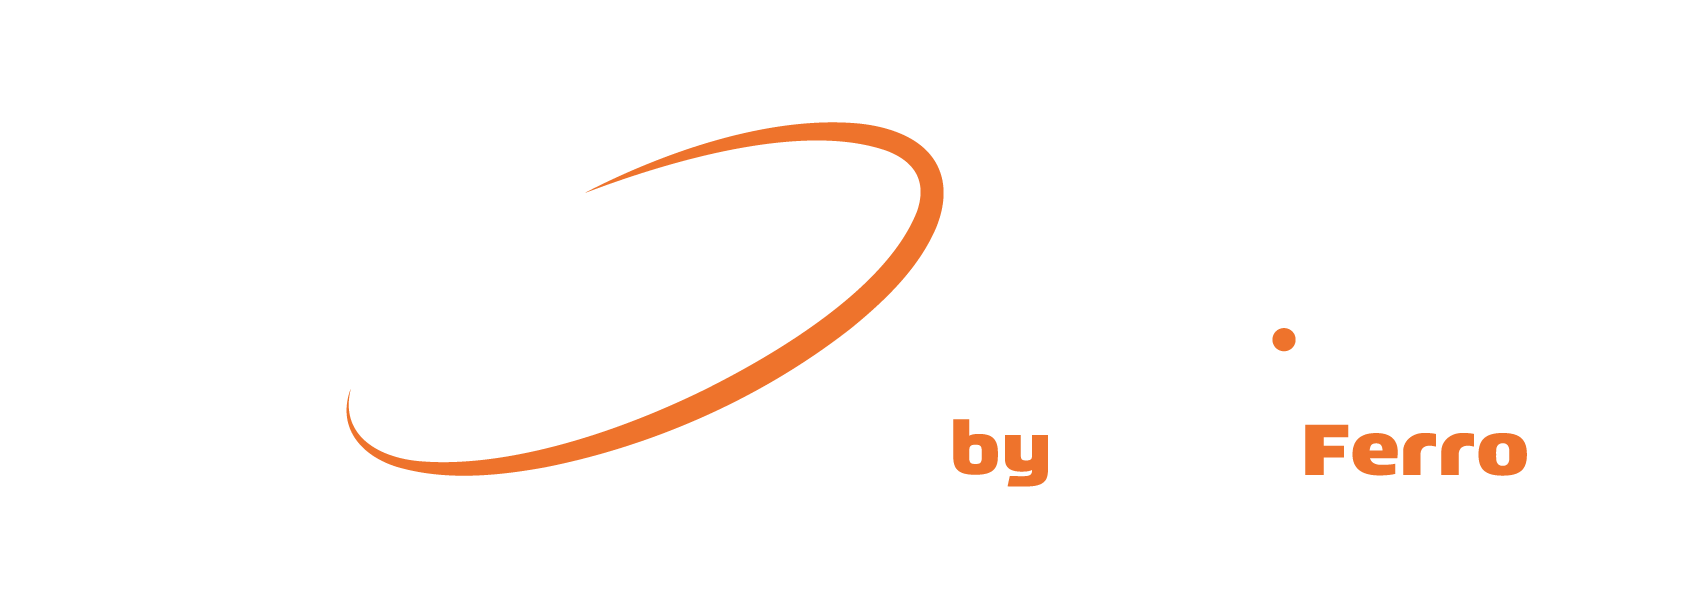
  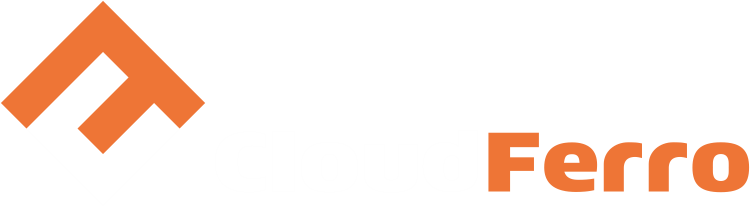
</div>

Run on [CREODIAS](https://creodias.eu), an Earth observation platform by [CloudFerro](https://cloudferro.com). The archive is mounted read only at `/eodata` on every CREODIAS virtual machine, so these notebooks read the source files in place.